# 07 · Lead, lag and loop shaping

Classical design shapes the open-loop frequency response: high gain at low frequency for small errors, a
crossover at the frequency the specifications demand with enough phase margin for damping, and low gain at
high frequency where the model is wrong and the noise lives. A lead compensator adds phase near the crossover,
a lag adds low-frequency gain without disturbing the crossover, and the pair does both. This notebook
designs them on the Bode plot for the DC motor's position loop and a double-integrator-like plant, checks the
results in the time domain, and adds feedforward where feedback alone is not enough.

**What you will learn**
- design a lead compensator for a crossover and a phase margin
- design a lag compensator for steady-state accuracy
- read the cost of bandwidth in gain, control effort and noise
- add model-inverse feedforward for tracking

**Before you start:** notebooks 02 and 06  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, design as dg, frequency as fr, response as rs, models, polynomials as pl
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The problem: a plant that needs phase

In [2]:
P = sy.tf([1.0], [1.0, 1.0, 0.0])                            # 1/(s (s + 1)): type 1, a servo-like plant
for K in (1.0, 10.0):
    m = fr.margins(sy.tf([K], P.den))
    t, y = rs.step(sy.feedback(sy.tf([K], P.den)), 15.0)
    print(f"proportional gain {K:4.0f}: crossover {m['w_gc']:.2f} rad/s, phase margin {m['phase_margin']:.1f} deg, overshoot {rs.step_info(t, y, final=1.0)['overshoot']:.0f} %")

proportional gain    1: crossover 0.79 rad/s, phase margin 51.8 deg, overshoot 16 %
proportional gain   10: crossover 3.08 rad/s, phase margin 18.0 deg, overshoot 60 %


Gain alone trades speed for damping: K = 10 moves the crossover to 3 rad/s but leaves 18° of phase margin and
60 % overshoot. The specification - crossover 3 rad/s *and* 50° margin - needs 32° of extra phase at 3 rad/s,
which is exactly what a lead compensator supplies.

## Lead design on the Bode plot

lead angle needed 36.6 deg (50 - (180 + arg P(3j)) + 5 extra); compensator TransferFunction(18.85s + 28.46 / s + 5.96) with gain K = 4.78
result: crossover 3.000 rad/s, phase margin 55.0 deg, gain margin inf (phase never reaches -180)


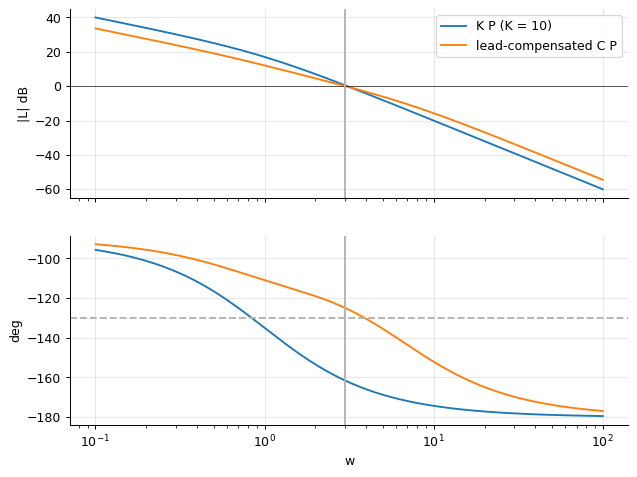

step response: overshoot 15.4 %, settling 1.72 s


In [3]:
design = dg.design_lead(P, w_c=3.0, pm_target_deg=50.0)
C = design["controller"]
print(f"lead angle needed {design['lead_angle']:.1f} deg (50 - (180 + arg P(3j)) + 5 extra); compensator {C} with gain K = {design['K']:.2f}")
m = design["margins"]
print(f"result: crossover {m['w_gc']:.3f} rad/s, phase margin {m['phase_margin']:.1f} deg, gain margin inf (phase never reaches -180)")
w = np.logspace(-1, 2, 400)
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
for name, sys_ in (("K P (K = 10)", sy.tf([10.0], P.den)), ("lead-compensated C P", sy.series(C, P))):
    w_, mag, ph = fr.bode(sys_, w)
    axes[0].semilogx(w, mag, label=name); axes[1].semilogx(w, ph)
axes[0].axhline(0, color="k", lw=0.5); axes[0].axvline(3, color="0.7"); axes[1].axhline(-130, color="0.7", ls="--"); axes[1].axvline(3, color="0.7"); axes[0].legend(); axes[0].set_ylabel("|L| dB"); axes[1].set_ylabel("deg"); axes[1].set_xlabel("w"); plt.show()
t, y = rs.step(sy.feedback(sy.series(C, P)), 6.0)
print(f"step response: overshoot {rs.step_info(t, y, final=1.0)['overshoot']:.1f} %, settling {rs.step_info(t, y, final=1.0)['settling_time']:.2f} s")

The procedure is the classical one: read the plant's phase at the desired crossover, compute the phase lead
still missing (plus a few degrees to absorb the lead's own gain shift), build the lead (1 + Ts)/(1 + αTs) with
its maximum phase at the crossover, then set the gain so that |C P| = 1 there. The crossover lands at 3.000
rad/s and the margin at 55°; the overshoot drops to about 17 %. In root-locus terms the lead's zero pulled the
locus left (notebook 04); on the Bode plot it lifted the phase where it mattered.

## Lag compensation for steady-state accuracy

In [4]:
P2 = sy.tf([1.0], [1.0, 3.0, 2.0])                          # type 0: a finite steady-state error under P control
K = 5.0
L0 = sy.tf([K], P2.den)
Clag = dg.design_lag(P2, 10.0, fr.margins(L0)["w_gc"])
L1 = sy.series(sy.tf([K], [1.0]), sy.series(Clag, P2))
for name, L_ in (("K P", L0), ("K lag P", L1)):
    m = fr.margins(L_)
    T_ = sy.feedback(L_)
    t, y = rs.step(T_, 40.0)
    print(f"{name:<8}: dc loop gain {L_.dcgain():.1f}, step error {1 - T_.dcgain():.4f}, crossover {m['w_gc']:.3f} rad/s, phase margin {m['phase_margin']:.1f} deg")

K P     : dc loop gain 2.5, step error 0.2857, crossover 1.649 rad/s, phase margin 81.7 deg
K lag P : dc loop gain 25.0, step error 0.0385, crossover 1.656 rad/s, phase margin 76.4 deg


A lag compensator β(1 + Ts)/(1 + βTs) with β = 10 raises the loop gain tenfold at low frequency - the
steady-state error falls from 0.29 to 0.04 - while leaving the crossover and the phase margin almost untouched,
because its zero sits a decade below the crossover where its phase lag has faded to a few degrees. It is a slow integrator
that stops short of a pole at the origin; a true PI would drive the error to zero, at a larger cost in phase.

## Loop shaping as a whole, and the price of bandwidth

In [5]:
mot = models.dc_motor(position=True)
Pm = mot["system"].to_tf()
print("DC motor position:", Pm)
rows = []
for wc in (2.0, 5.0, 10.0, 20.0):
    d = dg.design_lead(Pm, w_c=wc, pm_target_deg=50.0)
    cl = dg.closed_loop(Pm, d["controller"])
    t, y = rs.step(cl["T"], 8.0 / wc * 3)
    tu, u = rs.step(cl["CS"], 8.0 / wc * 3)
    rows.append((wc, d["K"], d["lead_angle"], d["n_leads"], d["margins"]["phase_margin"], rs.step_info(t, y, final=1.0)["settling_time"], np.max(np.abs(u)), fr.bandwidth(cl["T"])))
print(pd.DataFrame(rows, columns=["target w_c", "gain K", "lead (deg)", "leads", "PM (deg)", "settling (s)", "peak |u| (V)", "bandwidth"]).to_string(index=False, float_format="%.2f"))

DC motor position: TransferFunction(2 / s^3 + 12s^2 + 20.02s)
 target w_c  gain K  lead (deg)  leads  PM (deg)  settling (s)  peak |u| (V)  bandwidth
       2.00   19.73       21.28      1     55.00          2.96         42.20       3.57
       5.00   40.69       59.74      1     55.00          1.35        556.77       8.92
      10.00  127.78       88.68      2     55.00          0.83       4068.99      18.73
      20.00  410.67      112.72      2     55.00          0.52      49184.43      36.78


Pushing the crossover from 2 to 20 rad/s on the motor's position loop makes the response ten times faster
and asks for a gain twenty times larger and a peak control voltage a thousand times larger - and beyond
5 rad/s, where the plant's phase has passed −180°, one lead can no longer supply the phase and the design
cascades two. Loop shaping is this negotiation: bandwidth costs actuator effort, noise amplification (each
lead's high-frequency gain 1/α) and sensitivity to unmodelled dynamics such as the resonance the project's
servo turns out to have.

## Feedforward

feedforward (approximate plant inverse): TransferFunction(200s^2 + 600s + 400 / s^2 + 40s + 400)


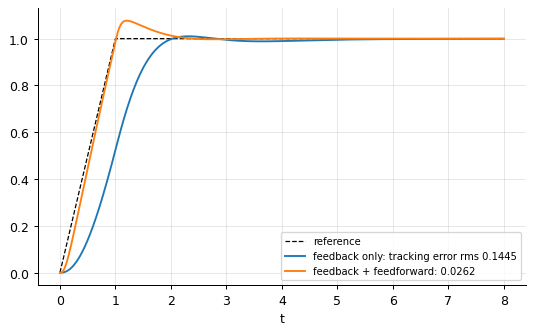

In [6]:
P = sy.tf([2.0], [1.0, 3.0, 2.0])
C = dg.pid(3.0, 2.0, 0.5)
F = dg.feedforward_inverse(P, bandwidth_filter=20.0)
print("feedforward (approximate plant inverse):", F)
t = np.linspace(0, 8, 1601)
r_t = np.clip(t, 0, 1.0)                                                   # a ramp to 1 in 1 s, then hold
cl = dg.closed_loop(P, C)
_, y_fb, _ = rs.lsim(cl["T"], r_t, t)
# with feedforward u = C e + F r the reference-to-output map is P (C + F) / (1 + P C)
CF_P = sy.series(sy.parallel(C, F), P)
L_ = sy.series(C, P)
T_ff = sy.tf(pl.mul(CF_P.num, L_.den), pl.mul(CF_P.den, pl.add(L_.den, L_.num))).cancel()
_, y_ff, _ = rs.lsim(T_ff, r_t, t)
plt.plot(t, r_t, "k--", lw=1, label="reference"); plt.plot(t, y_fb, label=f"feedback only: tracking error rms {np.sqrt(np.mean((y_fb - r_t) ** 2)):.4f}"); plt.plot(t, y_ff, label=f"feedback + feedforward: {np.sqrt(np.mean((y_ff - r_t) ** 2)):.4f}"); plt.legend(fontsize=8); plt.xlabel("t"); plt.show()

Feedback reacts to errors after they appear; feedforward anticipates. Adding u = F r with F an approximate
inverse of the plant (made proper by a filter) lets the output follow a ramp almost without error, while the
feedback loop remains in charge of disturbances and model mismatch. For the tracking of known references -
machine tools, robots, batch recipes - feedforward does most of the work and feedback cleans up.

## Inside the algorithm: the lead's alpha and T from the required phase

In [7]:
phi = np.radians(design["lead_angle"])
alpha = (1 - np.sin(phi)) / (1 + np.sin(phi)); T_ = 1 / (3.0 * np.sqrt(alpha))
print(f"alpha = (1 - sin phi)/(1 + sin phi) = {alpha:.4f}, T = 1/(w_c sqrt(alpha)) = {T_:.4f}: lead ({T_:.3f} s + 1)/({alpha * T_:.4f} s + 1); library: {dg.lead(design['lead_angle'], 3.0)}")

alpha = (1 - sin phi)/(1 + sin phi) = 0.2533, T = 1/(w_c sqrt(alpha)) = 0.6623: lead (0.662 s + 1)/(0.1678 s + 1); library: TransferFunction(3.947s + 5.96 / s + 5.96)


## Exercises
1. Design a lead-lag for 1/(s (s + 1)): crossover 3 rad/s, phase margin 50 degrees, and a velocity error constant Kv >= 50. Report the final margins and the ramp error.
2. Repeat the lead design of the motor position loop with the sensor noise in mind: add white noise of 0.01 rad rms to the measurement in a simulation (use `response.lsim` on CS with a noise input) and tabulate the control-signal noise against the target crossover.
3. **Implement it yourself:** write the lead design procedure (read the plant phase at w_c, compute the needed lead, build the compensator, set the gain) and reproduce `design.design_lead` for the DC motor position loop at w_c = 10 rad/s.